## Test Day

00: SPX 2024-12-26: Enriched 10425 of 11435 raw options across 52 expiries, of which the following 7 were dropped: 2025-02-10pm, 2025-05-16pm, 2025-05-30pm, 2026-03-20am, 2026-06-18am, 2028-12-15am and 2029-12-21am.


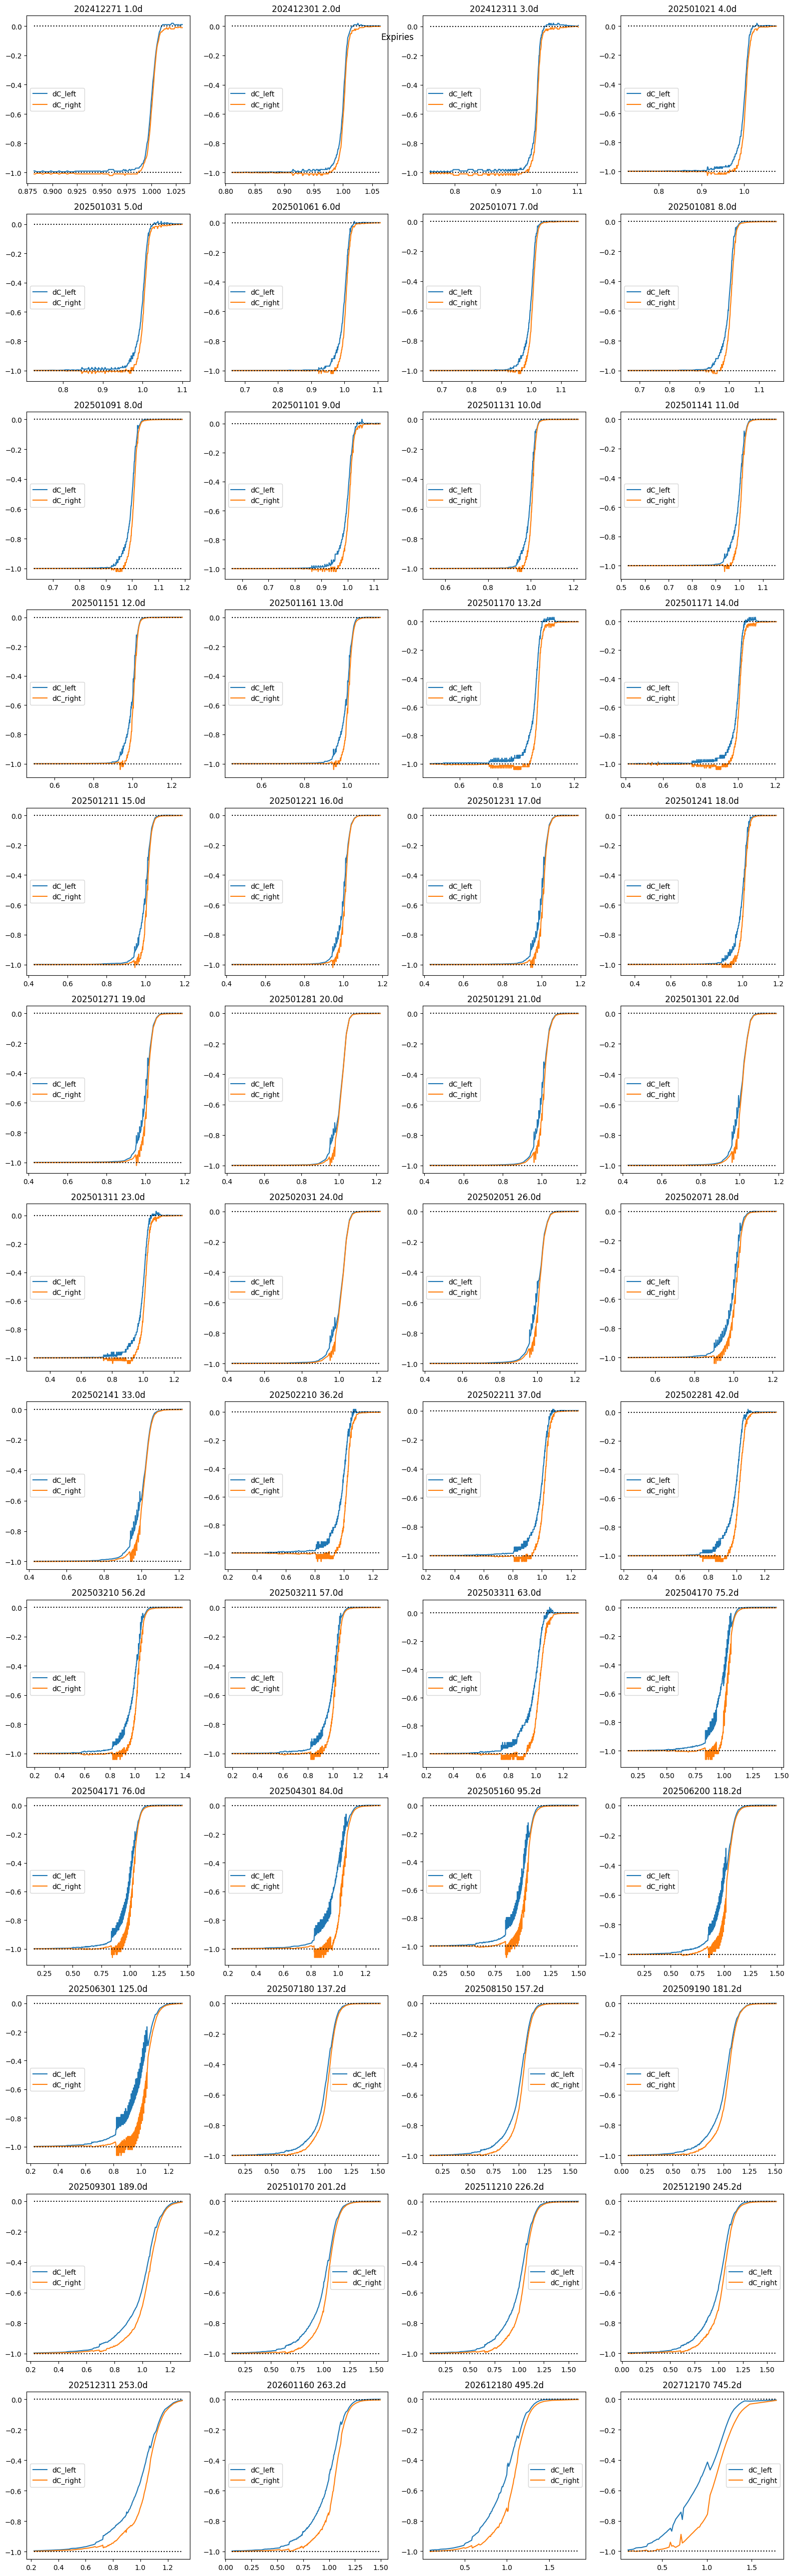

00: SPX 2024-12-26: Generating arb-free price surface.
01:   Expiry #0 1.000d: generating extended strikes... removed 80 out of 161 strikes to ensure -1 < dC/dK[0] and dC/dK[-1] < 0.
01:   SPX 2024-12-26: Expiry #0 1.00d: finding linear no-arbitrage mid... cannot find no-arbitrage mid (infeasible problem). This indicates actionable arbitrage in the input data -- removing expiry.
01:   Expiry #1 2.000d: generating extended strikes... removed 16 out of 163 strikes to ensure -1 < dC/dK[0] and dC/dK[-1] < 0.
01:   SPX 2024-12-26: Expiry #1 2.00d: finding linear no-arbitrage mid... 

/mnt/c/Users/hans/OneDrive/Python3/quant_data/quantdata/utils/arbfree.py:332: UserWarning: SPX 2024-12-26: Cannot find no-arbitrage mid for expiry 1.00d (infeasible problem). This indicates actionable arbitrage in the input data -- removing expiry.


01:   SPX 2024-12-26: Expiry #1 2.00d: finding linear no-arbitrage mid... cannot find no-arbitrage mid (infeasible problem). This indicates actionable arbitrage in the input data -- removing expiry.
01:   Expiry #2 3.000d: generating extended strikes... removed 68 out of 383 strikes to ensure -1 < dC/dK[0] and dC/dK[-1] < 0.
01:   SPX 2024-12-26: Expiry #2 3.00d: finding linear no-arbitrage mid... 

/mnt/c/Users/hans/OneDrive/Python3/quant_data/quantdata/utils/arbfree.py:332: UserWarning: SPX 2024-12-26: Cannot find no-arbitrage mid for expiry 2.00d (infeasible problem). This indicates actionable arbitrage in the input data -- removing expiry.


01:   SPX 2024-12-26: Expiry #2 3.00d: finding linear no-arbitrage mid... cannot find no-arbitrage mid (infeasible problem). This indicates actionable arbitrage in the input data -- removing expiry.
01:   Expiry #3 4.000d: generating extended strikes... removed 11 out of 165 strikes to ensure -1 < dC/dK[0] and dC/dK[-1] < 0.
01:   SPX 2024-12-26: Expiry #3 4.00d: finding linear no-arbitrage mid... 

/mnt/c/Users/hans/OneDrive/Python3/quant_data/quantdata/utils/arbfree.py:332: UserWarning: SPX 2024-12-26: Cannot find no-arbitrage mid for expiry 3.00d (infeasible problem). This indicates actionable arbitrage in the input data -- removing expiry.


01:   Expiry #4 5.000d: generating extended strikes... removed 18 out of 226 strikes to ensure -1 < dC/dK[0] and dC/dK[-1] < 0.
01:   Expiry #5 6.000d: generating extended strikes... removed 16 out of 156 strikes to ensure -1 < dC/dK[0] and dC/dK[-1] < 0.
01:   Expiry #6 7.000d: generating extended strikes... removed 15 out of 154 strikes to ensure -1 < dC/dK[0] and dC/dK[-1] < 0.
01:   Expiry #7 8.000d: generating extended strikes... removed 14 out of 151 strikes to ensure -1 < dC/dK[0] and dC/dK[-1] < 0.
01:   Expiry #8 8.000d: generating extended strikes... removed 15 out of 151 strikes to ensure -1 < dC/dK[0] and dC/dK[-1] < 0.
01:   Expiry #9 9.000d: generating extended strikes... removed 14 out of 205 strikes to ensure -1 < dC/dK[0] and dC/dK[-1] < 0.
01:   Expiry #10 10.000d: generating extended strikes... removed 16 out of 142 strikes to ensure -1 < dC/dK[0] and dC/dK[-1] < 0.
01:   Expiry #11 11.000d: generating extended strikes... removed 13 out of 140 strikes to ensure -1 < 

ValueError: SPX 2024-12-26: #15 14.000d: All ask prices must be greater than bid prices.

In [1]:
if False:
    import os
    os.environ["QUANTDATA_CACHE_MODE"] = "off" # turns off global cache mode; good for testing, but do not use in general.

%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.utils.arbfree
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.arbfree

from datetime import date

from cdxcore.dynaplot import figure
from quantdata.widb.day import collect_raw_day, enrich_day, ExpiryFilter, RawDayFilter
from quantdata.widb.arbfree import mk_arb_free_day, MkArbFree
from quantdata.biz_calendar import next_business_day, DAYS_PER_YEAR
from cdxcore.verbose import Context
from IPython.display import display
import numpy as np

def test():
    ticker = "SPX"
    d      = next_business_day( date(2024, 12, 26), count_start=True )

    raw_day_filter = RawDayFilter()
    expiry_filter = ExpiryFilter()
    verbose = Context.all

    raw_day = collect_raw_day(ticker, d, raw_day_filter=raw_day_filter, verbose=verbose, raise_if_bad=False)

    enr_day = enrich_day(ticker, d, raw_day, raw_day_filter=raw_day_filter, expiry_filter=expiry_filter, verbose=verbose, raise_if_bad=False)

    expiry_ids = enr_day['expiry_id'].to_numpy()
    unids = np.unique( expiry_ids )
    with figure("Expiries", row_size=4, col_size=4, columns=4) as fig:
        for uid in unids:
            tte_y = enr_day['tte_y'][ expiry_ids == uid ].iloc[0]
            ax = fig.add_subplot(f"{uid} {tte_y*DAYS_PER_YEAR:.1f}d")

            mask = enr_day['expiry_id'] == uid
            strikes = enr_day['pure_strike'][mask].to_numpy()
            bids = enr_day['pure_bid_price'][mask].to_numpy()
            asks = enr_day['pure_ask_price'][mask].to_numpy()

            dC_left = ( asks[1:] - bids[:-1] ) / ( strikes[1:] - strikes[:-1] )
            dC_right = ( asks[:-1] - bids[1:] ) / ( strikes[:-1] - strikes[1:] )

            ax.plot(strikes[1:], dC_left, label="dC_left")
            ax.plot(strikes[1:], dC_right, label="dC_right")
            ax.plot(strikes[1:], strikes[1:]*0-1., ":", color="black")
            ax.plot(strikes[1:], strikes[1:]*0, ":", color="black")
            ax.legend()

    arb_free = MkArbFree()
    arb_free = mk_arb_free_day(ticker, d, enr_day, mk_arb_free=arb_free, raw_day_filter=raw_day_filter, expiry_filter=expiry_filter, verbose=verbose, raise_if_bad=False, override_cache_mode="off")

    display(arb_free)
    return arb_free

_ = test()